# Preprocesamiento de Imágenes bajo CRISP-ML — Plátanos

- **Estudiante:** Hans Andre Perez Sequeiros (`222184@unamba.edu.pe`)
- **Curso:** Fundamentos de Inteligencia Artificial (AIS85) — UNAMBA
- **Etapa CRISP-ML:** Preparación de los datos (*Data Preparation*)

En este cuaderno aplicamos los pasos de limpieza, partición libre de fuga por captura base (`70% / 15% / 15%`), composición sobre fondo blanco, estandarización `224x224`, cálculo de pesos de clase y carga en TensorFlow/Keras.

### Paso 1. Importación de librerías y configuración de rutas

In [1]:
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

posibles_rutas = [
    Path.cwd().parent / 'dataset',
    Path.cwd() / 'dataset',
    Path(r'd:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\dataset'),
]
ruta_dataset = next((p for p in posibles_rutas if (p / 'train').exists() and (p / 'test').exists()), None)
if ruta_dataset is None:
    raise FileNotFoundError('No se encontró la carpeta dataset con subcarpetas train y test.')

ruta_exp = Path.cwd() if Path.cwd().name == 'experimento_hans_perez' else (
    Path.cwd() / 'experimento_hans_perez' if (Path.cwd() / 'experimento_hans_perez').exists()
    else Path(r'd:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\experimento_hans_perez')
)
ruta_figuras = ruta_exp / 'figuras_paper'
ruta_figuras.mkdir(parents=True, exist_ok=True)

ruta_salida = ruta_exp / 'dataset_preprocesado'
if ruta_salida.exists():
    shutil.rmtree(ruta_salida)

clases = ['freshbanana', 'rottenbanana']
mapa_etiquetas = {'freshbanana': 0, 'rottenbanana': 1}
print('Dataset origen:', ruta_dataset)
print('Carpeta de figuras:', ruta_figuras)
print('Carpeta de salida:', ruta_salida)

Dataset origen: d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\dataset
Carpeta de figuras: d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\experimento_hans_perez\figuras_paper
Carpeta de salida: d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\experimento_hans_perez\dataset_preprocesado


### Paso 2. Inventario completo e identificación de la fotografía base

In [2]:
def obtener_foto_base(nombre_archivo):
    """Extrae la captura base original ('Screen Shot ...') quitando prefijos como rotated_by_15_."""
    if 'Screen Shot' in nombre_archivo:
        return 'Screen Shot' + nombre_archivo.split('Screen Shot')[-1]
    return nombre_archivo

registros = []
for split_orig in ['train', 'test']:
    for clase in clases:
        carpeta = ruta_dataset / split_orig / clase
        for archivo in sorted(carpeta.iterdir()):
            if archivo.is_file() and archivo.suffix.lower() in {'.png', '.jpg', '.jpeg'}:
                registros.append({
                    'ruta': str(archivo),
                    'archivo': archivo.name,
                    'split_original': split_orig,
                    'clase': clase,
                    'etiqueta': mapa_etiquetas[clase],
                    'foto_base': obtener_foto_base(archivo.name),
                    'es_original': archivo.name.startswith('Screen Shot'),
                })

df = pd.DataFrame(registros)
assert df.groupby('foto_base')['clase'].nunique().max() == 1, 'Una captura base tiene más de una clase.'

bases_train_orig = set(df[df['split_original'] == 'train']['foto_base'])
bases_test_orig = set(df[df['split_original'] == 'test']['foto_base'])
print(f'Total de imágenes: {len(df):,}')
print(f'Capturas base únicas: {df["foto_base"].nunique()} ({df["es_original"].sum()} originales sin aumento)')
print(f'Capturas compartidas en Kaggle train/test: {len(bases_train_orig & bases_test_orig)}')

Total de imágenes: 4,716
Capturas base únicas: 524 (524 originales sin aumento)
Capturas compartidas en Kaggle train/test: 442


### Paso 3. Partición estratificada 70% / 15% / 15% por captura base (sin fuga de datos)

In [3]:
df_bases = df[['foto_base', 'clase', 'etiqueta']].drop_duplicates().reset_index(drop=True)

bases_train_val, bases_test = train_test_split(
    df_bases, test_size=0.15, stratify=df_bases['etiqueta'], random_state=SEED
)
bases_train, bases_val = train_test_split(
    bases_train_val, test_size=0.15 / 0.85, stratify=bases_train_val['etiqueta'], random_state=SEED
)

mapa_split = {}
for b in bases_train['foto_base']:
    mapa_split[b] = 'train'
for b in bases_val['foto_base']:
    mapa_split[b] = 'validation'
for b in bases_test['foto_base']:
    mapa_split[b] = 'test'

df['split'] = df['foto_base'].map(mapa_split)

s_tr = set(df[df['split'] == 'train']['foto_base'])
s_va = set(df[df['split'] == 'validation']['foto_base'])
s_te = set(df[df['split'] == 'test']['foto_base'])
assert len(s_tr & s_va) == 0 and len(s_tr & s_te) == 0 and len(s_va & s_te) == 0, 'Fuga detectada'

print('Capturas base por split -> train:', len(s_tr), '| validation:', len(s_va), '| test:', len(s_te))
print('\nImágenes por partición y clase:')
print(pd.crosstab(df['split'], df['clase'], margins=True, margins_name='Total'))
print('\nEvaluación canónica (solo capturas originales sin aumento):')
print(pd.crosstab(df[df['es_original']]['split'], df[df['es_original']]['clase'], margins=True))

Capturas base por split -> train: 366 | validation: 79 | test: 79

Imágenes por partición y clase:
clase       freshbanana  rottenbanana  Total
split                                       
test                297           414    711
train              1368          1926   3294
validation          297           414    711
Total              1962          2754   4716

Evaluación canónica (solo capturas originales sin aumento):
clase       freshbanana  rottenbanana  All
split                                     
test                 33            46   79
train               152           214  366
validation           33            46   79
All                 218           306  524


### Paso 4. Composición alfa sobre blanco, ajuste a `224x224` (`letterbox`) y generación de figura para Overleaf

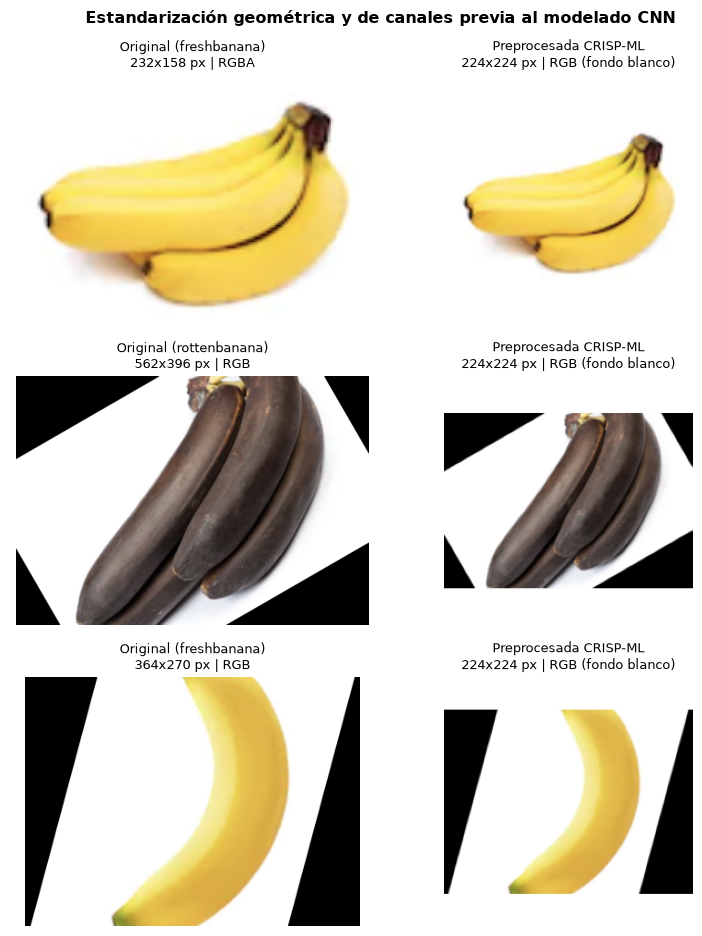

Figura guardada correctamente en: d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\experimento_hans_perez\figuras_paper\fig_antes_despues_224.png


In [4]:
TAMANO_OBJETIVO = (224, 224)

def preparar_imagen(ruta_img, tamano=TAMANO_OBJETIVO):
    """Corrige orientación EXIF, quita canal RGBA con fondo blanco y ajusta a 224x224 sin deformar."""
    with Image.open(ruta_img) as img:
        img = ImageOps.exif_transpose(img)
        if img.mode == 'RGBA':
            fondo = Image.new('RGB', img.size, (255, 255, 255))
            fondo.paste(img, mask=img.split()[3])
            img = fondo
        else:
            img = img.convert('RGB')
        return ImageOps.pad(img, tamano, method=Image.Resampling.BILINEAR, color=(255, 255, 255))

muestras_vis = pd.concat([
    df[(df['clase'] == 'freshbanana') & (df['es_original'])].sample(1, random_state=SEED),
    df[(df['clase'] == 'rottenbanana') & (~df['es_original'])].sample(1, random_state=SEED),
    df[(df['clase'] == 'freshbanana') & (~df['es_original'])].sample(1, random_state=SEED + 1),
])

fig, axes = plt.subplots(3, 2, figsize=(8, 9.5))
for fila, (_, row) in enumerate(muestras_vis.iterrows()):
    with Image.open(row['ruta']) as orig:
        modo_o, (wo, ho) = orig.mode, orig.size
        img_orig_rgb = orig.convert('RGB')
    img_proc = preparar_imagen(row['ruta'])

    axes[fila, 0].imshow(img_orig_rgb)
    axes[fila, 0].set_title(f'Original ({row["clase"]})\n{wo}x{ho} px | {modo_o}', fontsize=9.5)
    axes[fila, 0].axis('off')

    axes[fila, 1].imshow(img_proc)
    axes[fila, 1].set_title('Preprocesada CRISP-ML\n224x224 px | RGB (fondo blanco)', fontsize=9.5)
    axes[fila, 1].axis('off')

plt.suptitle('Estandarización geométrica y de canales previa al modelado CNN', fontsize=11.5, fontweight='bold')
plt.tight_layout()
ruta_fig6 = ruta_figuras / 'fig_antes_despues_224.png'
plt.savefig(ruta_fig6, dpi=300, bbox_inches='tight')
plt.show()
print('Figura guardada correctamente en:', ruta_fig6)

### Paso 5. Exportación de imágenes estandarizadas (`224x224`) y subconjuntos canónicos

In [5]:
for split_dir in ['train', 'validation', 'test', 'validation_canonico', 'test_canonico']:
    for clase in clases:
        (ruta_salida / split_dir / clase).mkdir(parents=True, exist_ok=True)

rutas_exportadas = []
total = len(df)
for i, (_, row) in enumerate(df.iterrows(), start=1):
    img_proc = preparar_imagen(row['ruta'])
    nombre_out = f"{i - 1:04d}_{Path(row['archivo']).stem}.png"
    dest = ruta_salida / row['split'] / row['clase'] / nombre_out
    img_proc.save(dest, format='PNG')
    if row['es_original'] and row['split'] in ('validation', 'test'):
        dest_can = ruta_salida / f"{row['split']}_canonico" / row['clase'] / nombre_out
        img_proc.save(dest_can, format='PNG')
    rutas_exportadas.append(str(dest))
    if i % 1000 == 0 or i == total:
        print(f'Progreso de exportación: {i:,} / {total:,} imágenes procesadas...')

df['ruta_salida'] = rutas_exportadas
df.to_csv(ruta_exp / 'particiones_crisp_ml.csv', index=False)
print(f'Exportación finalizada en: {ruta_salida}')

Progreso de exportación: 1,000 / 4,716 imágenes procesadas...
Progreso de exportación: 2,000 / 4,716 imágenes procesadas...
Progreso de exportación: 3,000 / 4,716 imágenes procesadas...
Progreso de exportación: 4,000 / 4,716 imágenes procesadas...
Progreso de exportación: 4,716 / 4,716 imágenes procesadas...
Exportación finalizada en: d:\OCTAVO SEMESTRE SISTEMAS\Proyecto de IA\proyecto-bananos\proyecto-bananos\experimento_hans_perez\dataset_preprocesado


### Paso 6. Pesos de clase balanceados (calculados solo sobre `train`)

In [6]:
y_train = df[df['split'] == 'train']['etiqueta'].values
pesos = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)
dict_pesos = {0: round(float(pesos[0]), 4), 1: round(float(pesos[1]), 4)}

print('Pesos de clase para entrenamiento (0=freshbanana, 1=rottenbanana):')
print(dict_pesos)

Pesos de clase para entrenamiento (0=freshbanana, 1=rottenbanana):
{0: 1.2039, 1: 0.8551}


### Paso 7. Pipeline de entrada en TensorFlow/Keras listo para CNN y Transfer Learning

In [7]:
BATCH_SIZE = 32
normalizar = tf.keras.layers.Rescaling(1.0 / 255.0)

def crear_dataset(subcarpeta, mezclar=False):
    ds = tf.keras.utils.image_dataset_from_directory(
        ruta_salida / subcarpeta,
        class_names=clases,
        label_mode='binary',
        image_size=TAMANO_OBJETIVO,
        batch_size=BATCH_SIZE,
        shuffle=mezclar,
        seed=SEED if mezclar else None,
    )
    return ds.map(lambda x, y: (normalizar(x), y)).prefetch(tf.data.AUTOTUNE)

ds_train = crear_dataset('train', mezclar=True)
ds_val = crear_dataset('validation', mezclar=False)
ds_test = crear_dataset('test', mezclar=False)
ds_test_canonico = crear_dataset('test_canonico', mezclar=False)

for lote_x, lote_y in ds_train.take(1):
    print('Forma de un lote train:', lote_x.shape, '| etiquetas:', lote_y.shape)
    print('Tipo de dato:', lote_x.dtype, '| Rango normalizado:', float(tf.reduce_min(lote_x)), 'a', float(tf.reduce_max(lote_x)))

print('\nPreprocesamiento CRISP-ML completado. Datasets listos para la fase de modelado (CNN / Transfer Learning).')

Found 3294 files belonging to 2 classes.
Found 711 files belonging to 2 classes.
Found 711 files belonging to 2 classes.
Found 79 files belonging to 2 classes.
Forma de un lote train: (32, 224, 224, 3) | etiquetas: (32, 1)
Tipo de dato: <dtype: 'float32'> | Rango normalizado: 0.0 a 1.0

Preprocesamiento CRISP-ML completado. Datasets listos para la fase de modelado (CNN / Transfer Learning).
